# Workshop 3: data quality findings in the Silver layer (Team 5, Extreme Weather Monitoring, Texas)

This notebook reviews every Parquet file written by the Silver DAG, plus the Bronze file names, and documents
the data quality issues we did not anticipate in Workshop 2. Each finding is the reason for one improvement of
the pipeline or for one governance KPI of the Gold layer (`src/gold/governance.py`).

Tools: pandas and matplotlib. Figures are saved to `workshop_3/figures/` for the report.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq

sys.path.insert(0, "..")   # project root, to import src/
from src.normalization import common, daily_summaries, storm_events, text

SILVER = Path("../datalake_silver")
BRONZE_PROCESSED = Path("../datalake_bronze/processed")
FIGURES = Path("../workshop_3/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def read_topic(topic):
    """Every Silver file of a topic, with the file name of each row (what Spark reads as one DataFrame)."""
    files = sorted(SILVER.glob(f"{topic}_*.parquet"))
    return pd.concat([pd.read_parquet(f).assign(silver_file=f.name) for f in files], ignore_index=True)


raw = {t: read_topic(t) for t in ["weather_alerts", "station_observations", "daily_summaries", "storm_events"]}
KEYS = {"weather_alerts": ["alert_id"], "station_observations": ["icao", "timestamp_utc"],
        "daily_summaries": ["ghcn_id", "date"], "storm_events": ["event_id"]}
latest = {t: df.sort_values(["ingested_at", "processed_at"]).drop_duplicates(KEYS[t], keep="last")
          for t, df in raw.items()}

## 1. Volume and schema consistency

Spark reads all the files of a topic as one DataFrame, so every file of a topic must have the same columns and
types. We compare the schema of each file with the first one.

In [2]:
rows = []
for topic in raw:
    files = sorted(SILVER.glob(f"{topic}_*.parquet"))
    reference = pq.read_schema(files[0])
    same = sum(pq.read_schema(f).equals(reference, check_metadata=False) for f in files)
    rows.append({"topic": topic, "files": len(files), "files_with_same_schema": same,
                 "rows_raw": len(raw[topic]), "distinct_keys": len(latest[topic]),
                 "columns": len(reference.names)})
volume = pd.DataFrame(rows).set_index("topic")
volume

,files,files_with_same_schema,rows_raw,distinct_keys,columns
topic,,,,,
weather_alerts,8,8,466,264,28
station_observations,9,9,1419,1362,22
daily_summaries,6,6,38124,38018,19
storm_events,4,4,40339,29051,26


**Finding 1 (schema):** every file of a topic has the same schema, so the folder read pattern works per topic.
The four topics have different schemas, so Gold reads `topic_*.parquet` one topic at a time and not the whole
`datalake_silver/` folder at once. KPI: *schema compliance rate*, kept as a preventive check.

## 2. Duplicates between runs

Silver skips a record when the same key **and** the same content hash is already stored. Even so, the 2025
Storm Events file was stored three times, once per NOAA compilation (the 2021-2024 years were loaded later, in
one file each).

In [3]:
dup = volume.assign(duplicated_rows=volume.rows_raw - volume.distinct_keys,
                    duplicate_rate_pct=(100 * (volume.rows_raw - volume.distinct_keys) / volume.rows_raw).round(2))
dup[["rows_raw", "distinct_keys", "duplicated_rows", "duplicate_rate_pct"]]

,rows_raw,distinct_keys,duplicated_rows,duplicate_rate_pct
topic,,,,
weather_alerts,466,264,202,43.35
station_observations,1419,1362,57,4.02
daily_summaries,38124,38018,106,0.28
storm_events,40339,29051,11288,27.98


In [4]:
storms = raw["storm_events"]
print(storms.groupby("silver_file").agg(rows=("event_id", "size"), source_file=("source_file", "first")))
example = storms[storms.event_id == storms.event_id.iloc[0]]
example[["event_id", "source_file", "damage_outlier", "record_hash", "silver_file"]]

                                       rows                                        source_file
silver_file                                                                                   
storm_events_20261117_010918.parquet   5641  StormEvents_details-ftp_v1.0_d2025_c20260819.c...
storm_events_20261119_021217.parquet   5647  StormEvents_details-ftp_v1.0_d2025_c20261118.c...
storm_events_20261120_153727.parquet   5647  StormEvents_details-ftp_v1.0_d2025_c20261119.c...
storm_events_20261120_164132.parquet  23404  StormEvents_details-ftp_v1.0_d2021_c20261119.c...


,event_id,source_file,damage_outlier,record_hash,silver_file
0,1230373,StormEvents_details-ftp_v1.0_d2025_c20260819.c...,False,696f375bd8ee5a2f74765f21d9efaf3dbefac108,storm_events_20261117_010918.parquet
5641,1230373,StormEvents_details-ftp_v1.0_d2025_c20261118.c...,False,5b41ad0e9645de5908154d5e03fed8af4f198d28,storm_events_20261119_021217.parquet
11288,1230373,StormEvents_details-ftp_v1.0_d2025_c20261119.c...,False,55b2859de50f8404b3a2a8a7b0acd0bd074083b4,storm_events_20261120_153727.parquet


The same event arrives with a different `source_file` (NOAA adds the compilation date `_cYYYYMMDD` to the file
name every time it re-publishes the year) and therefore with a different `record_hash`. The hash also included
the outlier flags, which are computed on the whole batch and change when the batch changes.

**Improvement (Silver):** the hash now covers only the values that come from the source. Each normalizer
declares `HASH_EXCLUDE` (file name, outlier flags, cleaned text), see `src/normalization/common.py`.
Below, the hash is recomputed on the same rows with the old and the new rule.

In [5]:
def versions(topic, module, exclude):
    df = raw[topic].drop(columns=common.METADATA_COLUMNS + ["silver_file"])
    hashed = common.add_record_hash(df.copy(), exclude=exclude)
    return hashed.drop_duplicates(module.KEY + ["record_hash"]).shape[0]


compare = pd.DataFrame({
    "rows_raw": [len(raw["storm_events"]), len(raw["daily_summaries"])],
    "versions_old_hash": [versions("storm_events", storm_events, []),
                          versions("daily_summaries", daily_summaries, [])],
    "versions_new_hash": [versions("storm_events", storm_events, storm_events.HASH_EXCLUDE),
                          versions("daily_summaries", daily_summaries, daily_summaries.HASH_EXCLUDE)],
    "distinct_keys": [len(latest["storm_events"]), len(latest["daily_summaries"])],
}, index=["storm_events", "daily_summaries"])
compare

,rows_raw,versions_old_hash,versions_new_hash,distinct_keys
storm_events,40339,40339,29104,29051
daily_summaries,38124,38025,38018,38018


**Finding 2 (duplicates):** with the new hash, Storm Events keeps one version per event plus the few events NOAA
really revised between compilations, and the daily duplicates disappear (they only had re-computed flags).
The files written before the fix keep their copies, so Gold keeps the latest version of each key.
KPI: *duplicate rate before and after de-duplication*.

## 3. Null and empty values per field

null_pct
topic                column                          
weather_alerts       ends_utc                   11.74
                     referenced_ids             45.08
                     centroid_lat               63.64
                     centroid_lon               63.64
station_observations temperature_c               0.07
                     relative_humidity_pct       0.07
                     wind_speed_ms               1.54
                     wind_gust_ms               99.56
                     wind_direction_deg          1.84
                     sea_level_pressure_hpa     83.26
                     precip_1h_mm              100.00
                     precip_3h_mm              100.00
                     text_description           11.23
daily_summaries      tmax_c                      0.24
                     tmin_c                      0.39
                     prcp_mm                     0.71
                     tmax_s_flag                 0.23
                     tmin_s_flag                 0.39
                     prcp_s_flag                 0.71
storm_events         begin_lat                  48.45
                     begin_lon                  48.45
                     magnitude                  52.57
                     magnitude_unit             52.57
                     magnitude_type             76.38
                     damage_property_usd        15.10
                     damage_crops_usd           13.86
                     narrative_clean            20.14

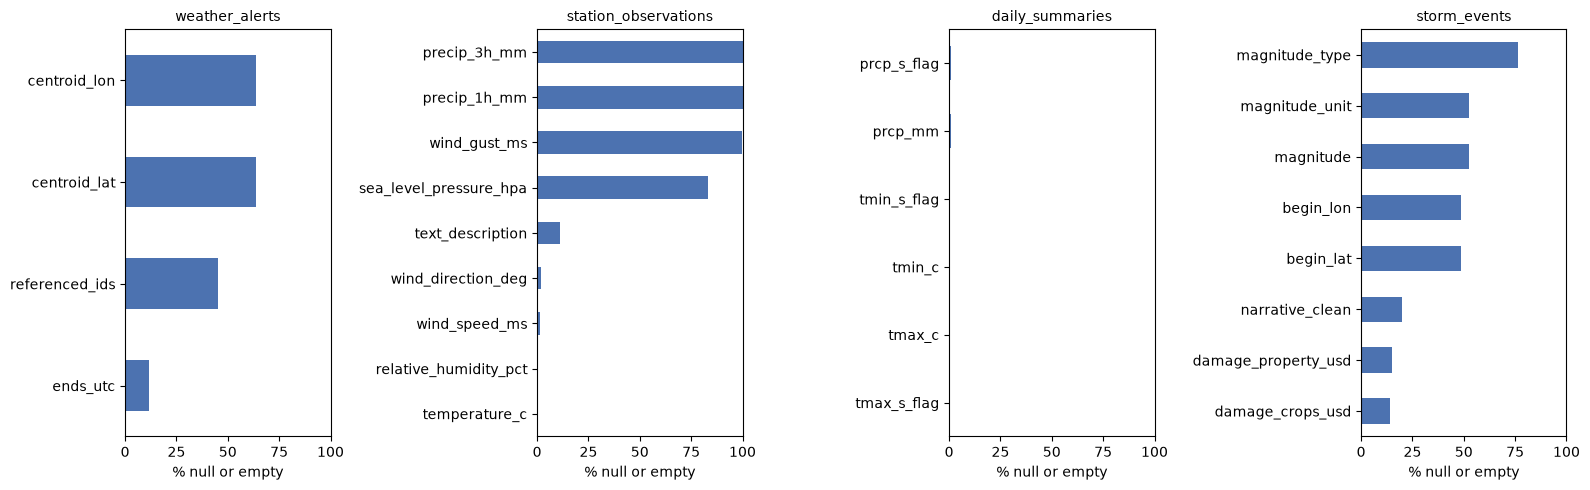

In [6]:
SKIP = {"record_hash", "bronze_file", "ingested_at", "processed_at", "silver_file", "out_of_range", "qc_failed"}


def empty_mask(values):
    """Null, NaN, blank text or empty list."""
    def is_empty(v):
        if v is None:
            return True
        if isinstance(v, str):
            return v.strip() == ""
        if hasattr(v, "__len__"):
            return len(v) == 0
        return pd.isna(v)
    return values.map(is_empty)


nulls = {t: pd.Series({c: 100 * empty_mask(df[c]).mean() for c in df.columns if c not in SKIP}).round(2)
         for t, df in latest.items()}
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, (topic, series) in zip(axes, nulls.items()):
    series[series > 0].sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.set_title(topic, fontsize=10)
    ax.set_xlabel("% null or empty")
    ax.set_xlim(0, 100)
fig.tight_layout()
fig.savefig(FIGURES / "null_rates.png", dpi=110)
pd.concat(nulls, names=["topic", "column"]).loc[lambda s: s > 0].to_frame("null_pct")

**Finding 3 (nulls):**

- F4 observations: `wind_gust_ms`, `precip_1h_mm` and `precip_3h_mm` are almost always null at our three
  stations, and `sea_level_pressure_hpa` is null in most rows. The API sends the field with `value: null`.
  These columns cannot feed the dashboard; precipitation comes from F2 instead.
- F1 Storm Events: latitude and longitude are null for forecast-zone rows (`cz_type = Z`, about half), as
  expected; magnitude only exists for hail and wind. Damage is null when NOAA left it blank (unknown, not zero).
- F3 alerts: about two thirds have no polygon (zone-based alerts), and `ends_utc` is missing mostly for
  Special Weather Statements.

KPI: *null rate per field*. Handling: keep the nulls (they mean "not reported"), never fill them with zero.

## 4. Outliers and quality flags

In [7]:
daily = latest["daily_summaries"].copy()
by_station = daily.groupby("icao", observed=True)
flags = pd.DataFrame({
    "tmax_outlier": by_station["tmax_outlier"].mean(),
    "tmin_outlier": by_station["tmin_outlier"].mean(),
    "prcp_outlier": by_station["prcp_outlier"].mean(),
    "qc_failed": by_station["qc_failed"].apply(lambda s: (s != "").mean()),
    "is_trace": by_station["is_trace"].mean(),
}).mul(100).round(3)
obs = latest["station_observations"]
print("F4 rows out of physical range:", int((obs.out_of_range != "").sum()),
      "| temperature Z-score outliers:", int(obs.temperature_outlier.sum()))
print("Storm Events damage outliers:", round(100 * latest["storm_events"].damage_outlier.mean(), 2), "%")
flags

F4 rows out of physical range: 0 | temperature Z-score outliers: 0
Storm Events damage outliers: 0.52 %


,tmax_outlier,tmin_outlier,prcp_outlier,qc_failed,is_trace
icao,,,,,
KAUS,0.694,0.034,2.040,0.017,12.652
KDFW,0.260,0.023,1.473,0.000,9.816
KIAH,0.870,0.084,2.320,0.000,12.289


,icao,date,prcp_mm,prcp_outlier
16843,KIAH,2017-08-27,408.2,True
4007,KAUS,2015-10-30,317.2,True
4510,KIAH,2016-04-18,252.0,True
19058,KIAH,2019-09-19,233.9,True
16188,KAUS,2016-05-26,223.3,True


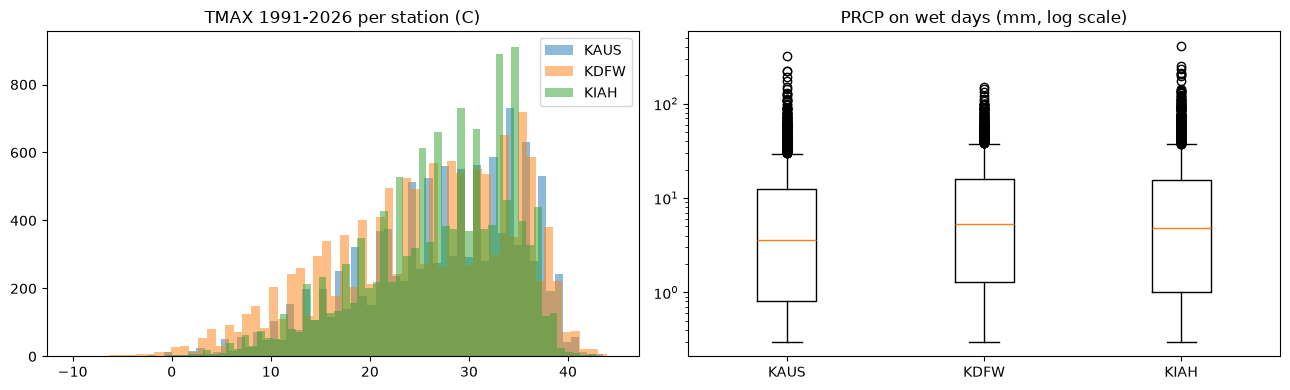

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for icao, group in daily.groupby("icao", observed=True):
    axes[0].hist(group.tmax_c.dropna(), bins=60, alpha=0.5, label=icao)
axes[0].set_title("TMAX 1991-2026 per station (C)")
axes[0].legend()
wet = daily[daily.prcp_mm > 0]
stations = ["KAUS", "KDFW", "KIAH"]
axes[1].boxplot([wet[wet.icao == s].prcp_mm for s in stations], tick_labels=stations)
axes[1].set_yscale("log")
axes[1].set_title("PRCP on wet days (mm, log scale)")
fig.tight_layout()
fig.savefig(FIGURES / "outliers.png", dpi=110)
daily.nlargest(5, "prcp_mm")[["icao", "date", "prcp_mm", "prcp_outlier"]]

**Finding 4 (outliers):** no observation broke the physical limits, and only two daily values were rejected by
NCEI quality flags (KAUS, March 1999). The IQR flags mark about 2 % of wet days and under 1 % of temperatures.
The largest value, 408 mm at KIAH on 2017-08-27, is Hurricane Harvey: an extreme value is the signal we look
for, so outliers are flagged and never removed. KPI: *outlier rate per numeric field*.

## 5. Text fields: length and noise

Storm narratives that are empty: 20.1 %
{'Hail': 1734, 'High Wind': 1020, 'Heat': 934, 'Drought': 668, 'Thunderstorm Wind': 549}


,alert description,storm narrative
count,264.0,29051.0
mean,498.7,165.8
std,341.2,295.0
min,20.0,0.0
25%,226.0,40.0
50%,430.0,84.0
75%,796.2,155.0
max,2661.0,3890.0


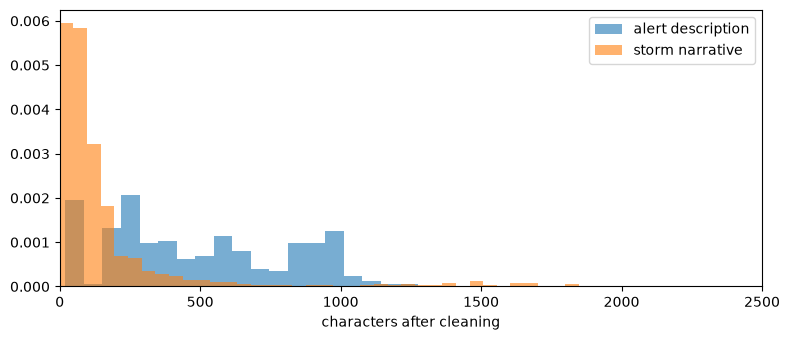

In [9]:
alerts = latest["weather_alerts"]
narr = latest["storm_events"]
lengths = pd.DataFrame({
    "alert description": alerts.description_clean.str.len().describe(),
    "storm narrative": narr.narrative_clean.str.len().describe(),
}).round(1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(alerts.description_clean.str.len(), bins=40, alpha=0.6, density=True, label="alert description")
ax.hist(narr.narrative_clean.str.len(), bins=80, alpha=0.6, density=True, label="storm narrative")
ax.set_xlim(0, 2500)
ax.set_xlabel("characters after cleaning")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "text_length.png", dpi=110)
print("Storm narratives that are empty:", round(100 * (narr.narrative_clean == "").mean(), 1), "%")
print(narr[narr.narrative_clean == ""].event_type.value_counts().head(5).to_dict())
lengths

In [10]:
# The Silver rows written in Workshop 2 still have the old tokens; the new rule is applied to the raw description.
old_tokens = alerts.description_tokens.explode().value_counts().head(20)
new_tokens = alerts.description.map(lambda d: text.tokenize(text.clean_text(d))).explode().value_counts().head(20)
print("Alerts with a link in the description:", int(alerts.description.str.contains("http", na=False).sum()))
pd.DataFrame({"before (Workshop 2)": old_tokens.index, "count": old_tokens.values,
              "after (Workshop 3)": new_tokens.index, "count ": new_tokens.values})

Alerts with a link in the description:

 46


,before (Workshop 2),count,after (Workshop 3),count
0,flooding,282,flooding,282
1,flood,279,flood,256
2,coastal,234,coastal,234
3,feet,232,feet,232
4,rip,224,rip,224
5,high,223,high,223
6,minor,222,minor,222
7,expected,211,expected,211
8,advisory,189,advisory,189
9,impacts,184,impacts,184


**Finding 5 (text):** alert descriptions are long bulletins (median about 430 characters); 20 % of storm
narratives are empty, mostly Hail, High Wind and Heat reports. Among the most frequent alert tokens were `cst` and `pm`,
and links like `http://www.weather.gov/safety/flood` left the fragments `http`, `www` and `gov`.

**Improvement (NLP preprocessing):** `clean_text` now removes links and e-mail addresses, and `tokenize` drops
time-zone and clock words, weekdays and pure numbers (`src/normalization/text.py`). KPI: *text length statistics*.
All texts are official NWS/NCEI English bulletins, so a language distribution KPI does not apply.

## 6. Ingestion frequency

,runs
0,
2026-11-17,6
2026-11-18,0
2026-11-19,2
2026-11-20,2


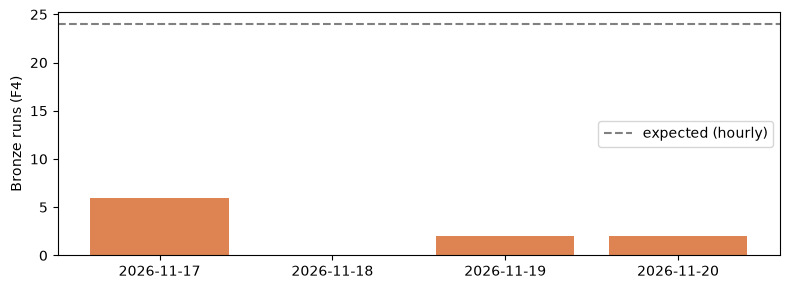

In [11]:
names = pd.Series([p.name for p in BRONZE_PROCESSED.glob("nws_observations_*.json")])
runs = pd.to_datetime(names.str.extract(r"_(\d{8}_\d{2})")[0], format="%Y%m%d_%H").drop_duplicates()
per_day = runs.dt.date.value_counts().sort_index()
calendar = pd.date_range(runs.min().normalize(), runs.max().normalize(), freq="D").date
per_day = per_day.reindex(calendar, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar([str(d) for d in per_day.index], per_day.values, color="#DD8452")
ax.axhline(24, color="grey", linestyle="--", label="expected (hourly)")
ax.set_ylabel("Bronze runs (F4)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "ingestion_runs.png", dpi=110)
per_day.to_frame("runs")

**Finding 6 (ingestion):** the Bronze DAG is hourly, but it only runs while Docker Desktop is open on a laptop,
and whole days have no runs. F3 and F4 cannot be recovered later (the NWS API keeps about 7 days), so those hours
are lost; `catchup=False` is still right because an old run would only see current data. KPIs: *ingestion
frequency compliance* (actual vs expected runs per day) and *freshness* (hours since the last record).

## 7. Station completeness of the daily history

icao,KAUS,KDFW,KIAH
year,,,
1992,78.0,366.0,366.0
1994,357.0,365.0,365.0
1995,347.0,365.0,365.0
1996,65.0,366.0,366.0
1997,60.0,365.0,365.0
2026,317.0,317.0,317.0


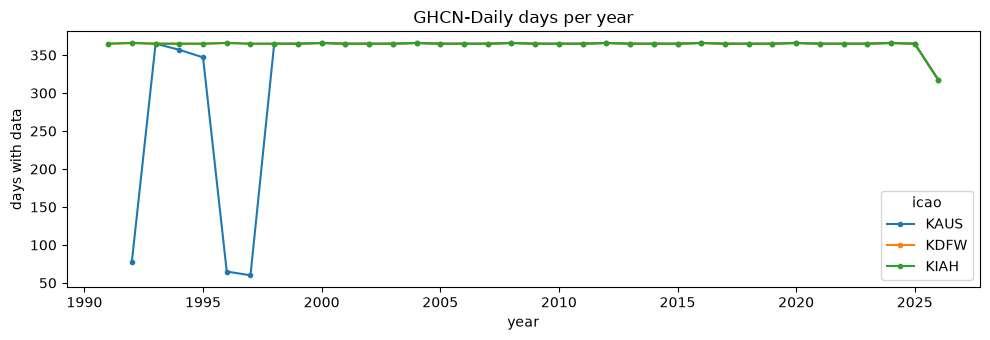

In [12]:
daily["year"] = daily.date.dt.year
days = daily.groupby(["year", "icao"], observed=True).size().unstack()
fig, ax = plt.subplots(figsize=(10, 3.5))
days.plot(ax=ax, marker=".")
ax.set_ylabel("days with data")
ax.set_title("GHCN-Daily days per year")
fig.tight_layout()
fig.savefig(FIGURES / "station_completeness.png", dpi=110)
days[days.min(axis=1) < 360]

**Finding 7 (completeness):**

- KAUS (Austin-Bergstrom) starts on 1992-10-15 and has only 65 and 60 days in 1996 and 1997, so its 1991-2020
  baseline has 26 complete years instead of 30. We keep the station and expose the number of baseline values
  (`baseline_n`) next to each class in Gold.
- In the first Gold test, 2026 only had its last 35 days: the Workshop 2 historical load covered 2025, and the
  incremental F2 extraction only looks 30 days back. We ran the historical load for 1991-2024 (baseline) and for
  2026, which closed the gap. KPI: *station completeness* (days present and nulls per station and year).
- F1 Storm Events only had 2025, while the Course Project asks for at least five years of each historical source
  where available (NOAA publishes from 1996). We loaded 2021-2024 (23,404 Texas events), so F1 covers 2021-2025.

## 8. Alert status and test messages

In [13]:
print(alerts.groupby(["status", "message_type"], observed=True).size().to_frame("alerts"))
alerts[alerts.status != "Actual"][["event", "status", "severity", "sender_name", "sent_utc"]]

                     alerts
status message_type        
Actual Alert            118
       Cancel            25
       Update           120
Test   Alert              1


,event,status,severity,sender_name,sent_utc
440,Tsunami Warning,Test,Extreme,NWS National Tsunami Warning Center,2026-11-17 17:29:00+00:00


**Finding 8 (test messages):** one alert in the Texas feed is a `Test` message, a TEST Tsunami Warning of the
National Tsunami Warning Center with severity Extreme. It is a valid CAP message, so Silver keeps it, but it is
not weather: Gold counts only `status = Actual` and leaves out Cancel messages. KPI: *alert status* (alerts per
CAP status and message type).

A smaller observation: GHCN-Daily stores temperatures in whole degrees Fahrenheit, so in Celsius they move in
steps of about 0.56 degrees and the same value often repeats for several days (38.3 C is 101 F). This is the
resolution of the source, not a stuck sensor.

## 9. Summary of findings

| # | Field / topic | Issue | Severity | Handling | KPI |
|---|---|---|---|---|---|
| 1 | all topics | 4 different schemas in one folder | high for Spark | read per topic, schema check | schema compliance |
| 2 | storm_events, daily_summaries | copies of unchanged records between runs | high (67 % of the 2025 F1 rows) | hash on source fields, Gold keeps latest version | duplicate rate |
| 3 | F4 gust, precipitation, sea-level pressure; F1 coordinates; F3 geometry | mostly null | medium | keep null, not used in charts | null rate per field |
| 4 | daily values, damage | extreme values (Harvey) | low | flag, never remove | outlier rate |
| 5 | alert descriptions, narratives | links and time words as tokens; 20 % empty narratives | medium | link and noise removal | text length |
| 6 | F3, F4 | days without hourly runs | high (data lost) | documented, Docker on while working | ingestion compliance, freshness |
| 7 | F2 KAUS and 2026, F1 years | gaps in the KAUS baseline, missing months of 2026, F1 with one year | high for the indicator | historical loads, baseline_n | station completeness |
| 8 | F3 status | a Test message with severity Extreme | medium (false Extreme alert) | Gold uses status = Actual | alert status |